# CALCE CX2 — LatentTSF-inspired next-cycle SOH forecasting

**Experiment A | ICML 2026-inspired architecture | PyTorch | Five existing charging indicators**

This notebook is an **adaptation**, not a line-by-line reproduction of Yang et al., *From Observations to States: Latent Time Series Forecasting* (ICML 2026): https://proceedings.mlr.press/v306/yang26y.html . The official code is at https://github.com/Muyiiiii/LatentTSF .

**Paper's central idea:** pretrain an autoencoder on observed signals, freeze it, then forecast future observations in latent space using both latent prediction and latent alignment objectives.

**Our adaptation:**
1. Fit a five-feature scaler **only on filtered training cells**.
2. Pretrain an observation autoencoder using **only the five input features** (never SOH targets).
3. Freeze the autoencoder; forecast the next observed battery-feature latent state from the prior 12 consecutive cycles.
4. Regress the next cycle's SOH from the **predicted** latent state. Optional latent MSE + alignment regularize the forecaster.
5. Compare against a direct Transformer and a latent model without auxiliary latent loss on **exactly the same forecasting windows**.

### Critical evaluation distinction
In earlier notebooks, the model received **current-cycle features** and predicted **current-cycle SOH**. Here the input is cycles `t-L ... t-1`, and the output is **SOH at cycle t**. At inference time, current/future-cycle features are NOT given to the model. **Do not compare this notebook's RMSE directly with the previous 0.012754 RMSE.** Compare models *inside this notebook*.

Battery splits stay disjoint; removed-cycle boundaries are never bridged. Timestamps may be used only to break windows; recording gaps are not assumed to represent rest. This model does not establish that latent states are physically identifiable degradation states.

In [1]:
# Execute once if necessary in a notebook:
# %pip install torch numpy pandas matplotlib scikit-learn
from pathlib import Path
import json, time, random, hashlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

DATA_DIR = Path(r"C:\Projects\Battery_Soh\pre processed ready to use data")
TRAIN_FILE = "train_final_filtered.csv"
VAL_FILE = "validation.csv"
TEST_FILE = "test.csv"
OUT_DIR = Path("latenttsf_soh_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ["cc_duration_s", "cv_duration_s", "dva_peak", "ic_peak_voltage", "ic_peak_width"]
TARGET = "soh"
SEQ_LEN = 12
MAX_GAP_HOURS = None  # optionally 24.0; changes the evaluation population, keep fixed for all models
LATENT_DIM = 4
D_MODEL = 64
N_HEADS = 4
N_LAYERS = 2
DROPOUT = 0.1
BATCH_SIZE = 128
LR = 1e-3
WEIGHT_DECAY = 1e-4
AE_EPOCHS = 40
AE_PATIENCE = 8
EPOCHS = 80
PATIENCE = 15
SEEDS = (42, 123, 2026)
LAMBDA_LATENT = 0.1
LAMBDA_ALIGN = 0.1
NUM_WORKERS = 0  # Windows-friendly
MAX_TRAIN_BATCHES = None  # set to 2 only for a smoke test; not research metrics
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:",torch.__version__,"| Device:",DEVICE)
if DEVICE.type == "cuda": print("GPU:",torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128 | Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load filtered training data and verify battery-disjoint partitions

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def read_split(path):
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}. Set DATA_DIR correctly. Need full metadata CSV, not the five-column train.csv in the original ZIP.")
    df = pd.read_csv(path)
    needed = FEATURES+[TARGET,"battery","cycle_ordinal"]
    missing = sorted(set(needed)-set(df.columns))
    if missing: raise ValueError(f"{path.name}: missing columns {missing}; use full metadata CSV")
    if df.duplicated(["battery","cycle_ordinal"]).any(): raise ValueError("Duplicate battery + ordinal")
    if not np.isfinite(df[FEATURES+[TARGET,"cycle_ordinal"]].to_numpy(float)).all():
        raise ValueError(f"Non-finite features, SOH, or ordinal in {path.name}")
    if "cycle_start" in df:
        df["cycle_start"] = pd.to_datetime(df["cycle_start"],errors="coerce")
    return df.sort_values(["battery","cycle_ordinal"]).reset_index(drop=True)

paths = dict(train=DATA_DIR/TRAIN_FILE, validation=DATA_DIR/VAL_FILE, test=DATA_DIR/TEST_FILE)
splits = {k:read_split(p) for k,p in paths.items()}
for split,frame in splits.items(): print(split, len(frame), sorted(frame.battery.unique()))
for a,b in [("train","validation"),("train","test"),("validation","test")]:
    assert set(splits[a].battery).isdisjoint(set(splits[b].battery)),f"Leakage: {a}/{b}"

X_MEAN = splits['train'][FEATURES].mean().to_numpy(np.float32)
X_STD = splits['train'][FEATURES].std(ddof=0).to_numpy(np.float32)
X_STD = np.where(X_STD < 1e-8, 1., X_STD).astype(np.float32)
Y_MEAN = float(splits['train'].soh.mean())
Y_STD = max(float(splits['train'].soh.std(ddof=0)),1e-6)
print('SOH train mean/std:',Y_MEAN,Y_STD)
(OUT_DIR/'feature_target_scaler.json').write_text(json.dumps(dict(features=FEATURES,train_csv=TRAIN_FILE,mean=X_MEAN.tolist(),std=X_STD.tolist(),soh_mean=Y_MEAN,soh_std=Y_STD),indent=2))
(OUT_DIR/'input_hashes.json').write_text(json.dumps({k:sha256(p) for k,p in paths.items()},indent=2))

train 7690 ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation 1743 ['CX2_36']
test 1477 ['CX2_38']
SOH train mean/std: 0.7884527182561515 0.11274037832620551


243

## 2. Create **next-cycle** forecasting windows without crossing gaps

In [3]:
class NextCycleWindows(Dataset):
    """X: features at t-L ... t-1; y: measured SOH at t; x_future: five features at t,
    used only as a TRAINING/VALIDATION supervision target for the latent model, never as input.
    """
    def __init__(self, df):
        xx,yy,xf,rows=[],[],[],[]
        self.segments=[]
        for battery,cell in df.groupby('battery',sort=False):
            cell=cell.sort_values('cycle_ordinal').reset_index(drop=True)
            ords=cell.cycle_ordinal.to_numpy()
            boundary=np.diff(ords)!=1
            if MAX_GAP_HOURS is not None:
                if 'cycle_start' not in cell: raise ValueError('cycle_start required for MAX_GAP_HOURS')
                dt=cell.cycle_start.diff().dt.total_seconds().to_numpy()[1:]/3600.
                boundary |= (~np.isfinite(dt)) | (dt>MAX_GAP_HOURS) | (dt<0)
            edges=np.r_[0,np.flatnonzero(boundary)+1,len(cell)]
            for a,b in zip(edges[:-1],edges[1:]):
                part=cell.iloc[a:b]
                self.segments.append((battery,len(part)))
                if len(part)<SEQ_LEN+1: continue
                feat=(part[FEATURES].to_numpy(np.float32)-X_MEAN)/X_STD
                soh=part.soh.to_numpy(np.float32)
                for j in range(SEQ_LEN,len(part)):
                    xx.append(feat[j-SEQ_LEN:j])
                    xf.append(feat[j])
                    yy.append((float(soh[j])-Y_MEAN)/Y_STD)
                    rows.append({'battery':str(battery),'cycle_ordinal':int(part.iloc[j].cycle_ordinal), 'soh':float(soh[j])})
        if not xx: raise ValueError(f'No sequences of {SEQ_LEN} past cycles + one future target.')
        self.x=torch.from_numpy(np.stack(xx).astype(np.float32))
        self.y=torch.tensor(yy,dtype=torch.float32)
        self.x_future=torch.from_numpy(np.stack(xf).astype(np.float32))
        self.metadata=pd.DataFrame(rows)
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return self.x[i],self.y[i],self.x_future[i]

sets={k:NextCycleWindows(v) for k,v in splits.items()}
for k,ds in sets.items():
    print(f'{k:>10}: {len(ds):>5} next-cycle forecasts | {len(ds.segments)} uninterrupted segments | {len(splits[k])-len(ds)} non-target rows')
assert sets['train'].x.shape[1:]==(SEQ_LEN,len(FEATURES))

def loaders_for(seed):
    g=torch.Generator().manual_seed(seed)
    return {k:DataLoader(v,batch_size=BATCH_SIZE,shuffle=(k=='train'),generator=g if k=='train' else None,
                          pin_memory=(DEVICE.type=='cuda'),num_workers=NUM_WORKERS)
            for k,v in sets.items()}

def seed_all(s):
    random.seed(s);np.random.seed(s);torch.manual_seed(s)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(s)

# Confirm strictly past inputs, target corresponds to the immediately following ordinal.
print(sets['train'].metadata.head())

     train:  3641 next-cycle forecasts | 481 uninterrupted segments | 4049 non-target rows
validation:   861 next-cycle forecasts | 98 uninterrupted segments | 882 non-target rows
      test:   707 next-cycle forecasts | 92 uninterrupted segments | 770 non-target rows
  battery  cycle_ordinal       soh
0  CX2_16             14  0.938021
1  CX2_16             15  0.939152
2  CX2_16             32  0.934327
3  CX2_16             33  0.934347
4  CX2_16             47  0.932822


## 3. Pretrain an observation autoencoder on **training features only**

AE epoch=1 train_MSE=0.92607 val_RMSE=1.06655
AE epoch=10 train_MSE=0.03672 val_RMSE=0.23152
AE epoch=20 train_MSE=0.01755 val_RMSE=0.19022
AE epoch=30 train_MSE=0.00844 val_RMSE=0.12728
AE epoch=40 train_MSE=0.00559 val_RMSE=0.11523
Best AE validation reconstruction RMSE (standardized five-feature space): 0.11206337230074416


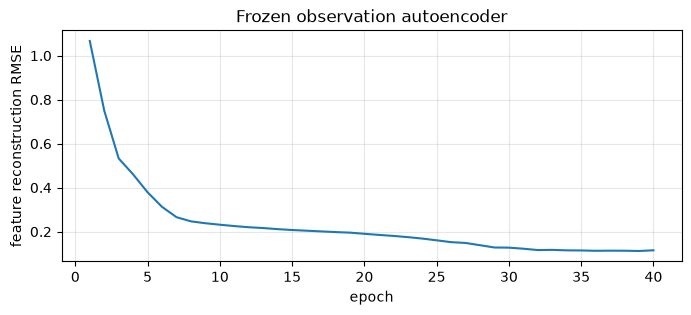

In [4]:
class ObservationAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(5,32),nn.GELU(),nn.Linear(32,LATENT_DIM))
        self.decoder=nn.Sequential(nn.Linear(LATENT_DIM,32),nn.GELU(),nn.Linear(32,5))
    def forward(self,x): return self.decoder(self.encoder(x))

seed_all(42)
ae=ObservationAE().to(DEVICE)
ae_opt=torch.optim.AdamW(ae.parameters(),lr=1e-3,weight_decay=1e-5)
train_features=torch.from_numpy(((splits['train'][FEATURES].to_numpy(np.float32)-X_MEAN)/X_STD)).float()
val_features=torch.from_numpy(((splits['validation'][FEATURES].to_numpy(np.float32)-X_MEAN)/X_STD)).float()
ae_loader=DataLoader(train_features,batch_size=256,shuffle=True,generator=torch.Generator().manual_seed(42),num_workers=0)

def reconstruct_rmse(model,data):
    model.eval();total=0.0;num=0
    with torch.no_grad():
        for b in DataLoader(data,batch_size=1024):
            b=b.to(DEVICE);p=model(b)
            total+=float((p-b).square().sum().item());num+=b.numel()
    return (total/num)**0.5

best=float('inf');wait=0;ae_hist=[];best_state=None
for epoch in range(1,AE_EPOCHS+1):
    ae.train();running=0;count=0
    for b in ae_loader:
        b=b.to(DEVICE);ae_opt.zero_grad(set_to_none=True)
        loss=F.mse_loss(ae(b),b)
        loss.backward();ae_opt.step();running+=float(loss.item())*len(b);count+=len(b)
        if MAX_TRAIN_BATCHES and count>=MAX_TRAIN_BATCHES*256: break
    val_rmse=reconstruct_rmse(ae,val_features)
    ae_hist.append(dict(epoch=epoch,train_MSE=running/max(count,1),val_reconstruction_RMSE=val_rmse))
    if val_rmse<best-1e-5:
        best=val_rmse;best_state=copy.deepcopy(ae.state_dict());wait=0
    else:
        wait+=1
        if wait>=AE_PATIENCE:break
    if epoch==1 or epoch%10==0: print(f'AE epoch={epoch} train_MSE={running/max(count,1):.5f} val_RMSE={val_rmse:.5f}')

ae.load_state_dict(best_state)
ae.eval()
for p in ae.parameters():p.requires_grad_(False)
torch.save(best_state,OUT_DIR/'observation_autoencoder.pt')
pd.DataFrame(ae_hist).to_csv(OUT_DIR/'ae_history.csv',index=False)
print('Best AE validation reconstruction RMSE (standardized five-feature space):',best)

with torch.no_grad():
    chunks=[ae.encoder(b.to(DEVICE)).cpu() for b in DataLoader(train_features,batch_size=2048)]
    Z=torch.cat(chunks).numpy()
Z_MEAN=Z.mean(0).astype(np.float32)
Z_STD=np.maximum(Z.std(0),0.05).astype(np.float32)
(OUT_DIR/'latent_scaler.json').write_text(json.dumps(dict(mean=Z_MEAN.tolist(),std=Z_STD.tolist()),indent=2))
plt.figure(figsize=(8,3));plt.plot([r['epoch'] for r in ae_hist],[r['val_reconstruction_RMSE'] for r in ae_hist]);plt.xlabel('epoch');plt.ylabel('feature reconstruction RMSE');plt.title('Frozen observation autoencoder');plt.grid(alpha=.3);plt.show()

## 4. Models: direct Transformer, latent regression, LatentTSF-inspired forecasting

In [5]:
class DirectTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed=nn.Linear(5,D_MODEL)
        self.pos=nn.Parameter(torch.zeros(1,SEQ_LEN,D_MODEL))
        layer=nn.TransformerEncoderLayer(D_MODEL,N_HEADS,dim_feedforward=128,dropout=DROPOUT,
                                        batch_first=True,activation='gelu',norm_first=True)
        self.net=nn.TransformerEncoder(layer,N_LAYERS,enable_nested_tensor=False)
        self.head=nn.Sequential(nn.LayerNorm(D_MODEL),nn.Linear(D_MODEL,32),nn.GELU(),nn.Linear(32,1))
    def forward(self,x):
        h=self.net(self.embed(x)+self.pos)
        return self.head(h[:,-1]).squeeze(-1),None

class LatentSOHForecaster(nn.Module):
    def __init__(self,ae_state):
        super().__init__()
        self.ae=ObservationAE()
        self.ae.load_state_dict(ae_state)
        self.ae.eval()
        for p in self.ae.parameters():p.requires_grad_(False)
        self.register_buffer('z_mean',torch.from_numpy(Z_MEAN.copy()))
        self.register_buffer('z_std',torch.from_numpy(Z_STD.copy()))
        self.embed=nn.Linear(LATENT_DIM,D_MODEL)
        self.pos=nn.Parameter(torch.zeros(1,SEQ_LEN,D_MODEL))
        layer=nn.TransformerEncoderLayer(D_MODEL,N_HEADS,dim_feedforward=128,dropout=DROPOUT,
                                        batch_first=True,activation='gelu',norm_first=True)
        self.net=nn.TransformerEncoder(layer,N_LAYERS,enable_nested_tensor=False)
        self.z_head=nn.Sequential(nn.LayerNorm(D_MODEL),nn.Linear(D_MODEL,32),nn.GELU(),nn.Linear(32,LATENT_DIM))
        self.soh_head=nn.Sequential(nn.Linear(LATENT_DIM,32),nn.GELU(),nn.Linear(32,1))
    def z_normalize(self,z):return (z-self.z_mean)/self.z_std
    def encode_observed(self,x):
        # encoder is frozen: no SOH labels nor future values flow into the input branch
        with torch.no_grad():return self.z_normalize(self.ae.encoder(x))
    def forward(self,x):
        z=self.encode_observed(x)     # [batch, past length, latent]
        h=self.net(self.embed(z)+self.pos)
        z_next=self.z_head(h[:,-1])  # forecast of future feature latent
        pred_soh=self.soh_head(z_next).squeeze(-1)
        return pred_soh,z_next

MODELS=('direct_transformer','latent_soh_only','latenttsf_aux')

def make_model(name):
    if name=='direct_transformer':return DirectTransformer().to(DEVICE)
    return LatentSOHForecaster(best_state).to(DEVICE)

def objective(name,model,xb,yb,xf):
    pred,z_pred=model(xb)
    label_loss=F.mse_loss(pred,yb)       # SOH normalized by train target std
    latent_mse=torch.tensor(0.,device=DEVICE)
    align=torch.tensor(0.,device=DEVICE)
    if name=='latenttsf_aux':
        z_true=model.encode_observed(xf) # future feature observation: SUPERVISION ONLY
        latent_mse=F.mse_loss(z_pred,z_true)
        align=(1-F.cosine_similarity(z_pred,z_true,dim=-1,eps=1e-8)).mean()
    total=label_loss+LAMBDA_LATENT*latent_mse+LAMBDA_ALIGN*align
    return total,label_loss,latent_mse,align

for name in MODELS:
    m=make_model(name)
    print(name,'trainable parameters:',sum(p.numel() for p in m.parameters() if p.requires_grad))
    xb,yb,xf=next(iter(loaders_for(42)['train']))
    with torch.no_grad(): y,z=m(xb.to(DEVICE))
    assert y.shape==yb.shape
    if z is not None:assert z.shape==(len(yb),LATENT_DIM)
print('Forward-pass shape tests successful.')

direct_transformer trainable parameters: 70337
latent_soh_only trainable parameters: 70565
latenttsf_aux trainable parameters: 70565
Forward-pass shape tests successful.


## 5. Train each architecture for three seeds; select only on validation RMSE

In [6]:
def evaluate(model,loader,collect=False):
    model.eval();yhat=[];ytrue=[];zhats=[]
    with torch.no_grad():
        for xb,yb,xf in loader:
            yh,z=model(xb.to(DEVICE))
            yhat.append((yh.cpu().numpy()*Y_STD+Y_MEAN))
            ytrue.append((yb.numpy()*Y_STD+Y_MEAN))
            if z is not None and collect: zhats.append(z.cpu().numpy())
    yt=np.concatenate(ytrue);yp=np.concatenate(yhat)
    err=yp-yt
    out=dict(RMSE=float(np.sqrt(np.mean(err**2))),MAE=float(np.mean(np.abs(err))),
             MAPE=float(100*np.mean(np.abs(err)/np.maximum(np.abs(yt),1e-6))),
             MBE=float(np.mean(err)),R2=float(1-np.sum(err**2)/max(np.sum((yt-yt.mean())**2),1e-12)))
    if collect:return out,yt,yp,np.concatenate(zhats) if zhats else None
    return out

runs=[];histories=[]
for name in MODELS:
    for seed in SEEDS:
        seed_all(seed)
        dl=loaders_for(seed)
        model=make_model(name)
        opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=LR,weight_decay=WEIGHT_DECAY)
        best_val=float('inf');best_model=None;best_ep=0;wait=0;hist=[]
        start=time.perf_counter()
        for ep in range(1,EPOCHS+1):
            model.train()
            # Freeze AE even when setting the rest of the model to train mode
            if hasattr(model,'ae'):model.ae.eval()
            accum=np.zeros(4);seen=0
            for batch_idx,(xb,yb,xf) in enumerate(dl['train']):
                xb=xb.to(DEVICE);yb=yb.to(DEVICE);xf=xf.to(DEVICE)
                opt.zero_grad(set_to_none=True)
                losses=objective(name,model,xb,yb,xf)
                losses[0].backward()
                nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad),1.0)
                opt.step()
                accum+=np.array([float(l.detach().item()) for l in losses])*len(yb)
                seen+=len(yb)
                if MAX_TRAIN_BATCHES is not None and batch_idx+1>=MAX_TRAIN_BATCHES:break
            v=evaluate(model,dl['validation'])
            hist.append(dict(epoch=ep,training_total_loss=accum[0]/max(1,seen),
                training_soh_loss=accum[1]/max(1,seen),training_latent_loss=accum[2]/max(1,seen),
                training_align_loss=accum[3]/max(1,seen),validation_RMSE=v['RMSE']))
            if v['RMSE']<best_val-1e-7:
                best_val=v['RMSE'];best_ep=ep;best_model=copy.deepcopy(model.state_dict());wait=0
            else:
                wait+=1
                if wait>=PATIENCE:break
            if ep==1 or ep%20==0:
                print(f'{name} seed={seed} epoch={ep} valRMSE={v["RMSE"]:.6f} best={best_val:.6f}')
        seconds=time.perf_counter()-start
        model.load_state_dict(best_model)
        torch.save(dict(model_state=best_model,name=name,seed=seed,best_epoch=best_ep,feature_order=FEATURES,
                        task='next_cycle_soh_forecasting'),OUT_DIR/f'{name}_seed{seed}.pt')
        pd.DataFrame(hist).to_csv(OUT_DIR/f'{name}_seed{seed}_history.csv',index=False)
        histories.extend([dict(model=name,seed=seed,**r) for r in hist])
        for split in ('train','validation','test'):
            met,yt,yp,z=evaluate(model,dl[split],collect=True)
            row=dict(model=name,seed=seed,split=split,best_epoch=best_ep,train_seconds=seconds,
                     trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),**met)
            runs.append(row)
            pred=sets[split].metadata.copy()
            pred['predicted_soh']=yp
            pred['error']=yp-yt
            pred.to_csv(OUT_DIR/f'{name}_seed{seed}_{split}_predictions.csv',index=False)
            if z is not None and split=='test':
                zdf=pd.DataFrame(z,columns=[f'z_pred_{i}' for i in range(LATENT_DIM)])
                pd.concat([pred.reset_index(drop=True),zdf],axis=1).to_csv(
                    OUT_DIR/f'{name}_seed{seed}_test_latent_predictions.csv',index=False)
        print(f'FINISHED {name} seed {seed}: best validation RMSE={best_val:.6f} epoch={best_ep}')

metrics=pd.DataFrame(runs)
metrics.to_csv(OUT_DIR/'metrics_all_runs.csv',index=False)
summary=(metrics.groupby(['split','model'],as_index=False)
             .agg(RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),
                  MAE_mean=('MAE','mean'),MAPE_mean=('MAPE','mean'),
                  R2_mean=('R2','mean'),training_seconds_mean=('train_seconds','mean'),n_seeds=('seed','nunique')))
summary.to_csv(OUT_DIR/'metrics_summary.csv',index=False)
pd.DataFrame(histories).to_csv(OUT_DIR/'histories_all.csv',index=False)
print('Validation leaderboard (USE FOR MODEL SELECTION)')
display(summary.query("split == 'validation'").sort_values('RMSE_mean'))
print('Held-out test (REPORT ONLY; do not optimize from these results)')
display(summary.query("split == 'test'").sort_values('RMSE_mean'))

direct_transformer seed=42 epoch=1 valRMSE=0.026022 best=0.026022
direct_transformer seed=42 epoch=20 valRMSE=0.015351 best=0.014949
direct_transformer seed=42 epoch=40 valRMSE=0.016695 best=0.013526
FINISHED direct_transformer seed 42: best validation RMSE=0.013526 epoch=28
direct_transformer seed=123 epoch=1 valRMSE=0.018533 best=0.018533
direct_transformer seed=123 epoch=20 valRMSE=0.015022 best=0.013202
FINISHED direct_transformer seed 123: best validation RMSE=0.013202 epoch=19
direct_transformer seed=2026 epoch=1 valRMSE=0.023530 best=0.023530
direct_transformer seed=2026 epoch=20 valRMSE=0.016732 best=0.016575
FINISHED direct_transformer seed 2026: best validation RMSE=0.014970 epoch=21
latent_soh_only seed=42 epoch=1 valRMSE=0.026922 best=0.026922
latent_soh_only seed=42 epoch=20 valRMSE=0.021966 best=0.021257
FINISHED latent_soh_only seed 42: best validation RMSE=0.021257 epoch=9
latent_soh_only seed=123 epoch=1 valRMSE=0.026724 best=0.026724
FINISHED latent_soh_only seed 123:

,split,model,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,training_seconds_mean,n_seeds
6,validation,direct_transformer,0.013899,0.000941,0.009444,1.411899,0.986888,16.013270,3
8,validation,latenttsf_aux,0.017943,0.001091,0.013494,1.908107,0.978160,9.049205,3
7,validation,latent_soh_only,0.020154,0.000980,0.015029,2.160868,0.972472,9.057660,3


Held-out test (REPORT ONLY; do not optimize from these results)


,split,model,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,training_seconds_mean,n_seeds
1,test,latent_soh_only,0.012898,0.001768,0.010276,1.397484,0.988982,9.057660,3
2,test,latenttsf_aux,0.014912,0.002945,0.011584,1.596558,0.985076,9.049205,3
0,test,direct_transformer,0.016627,0.001592,0.015249,2.015345,0.981805,16.013270,3


## 6. Visualizations and per-battery metrics

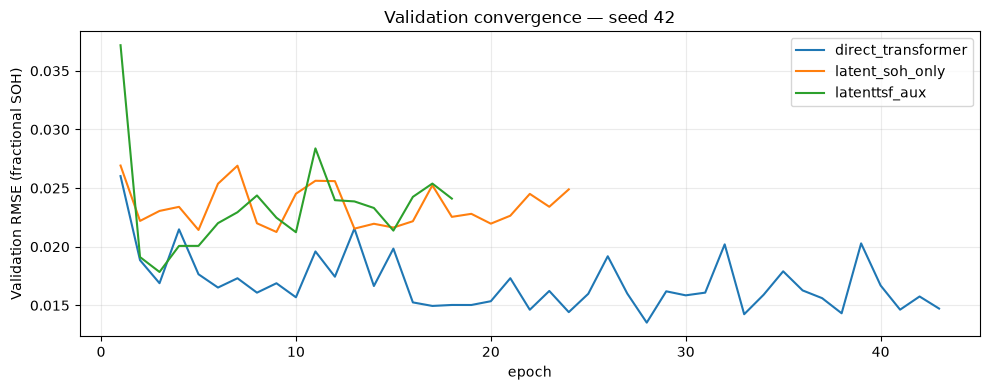

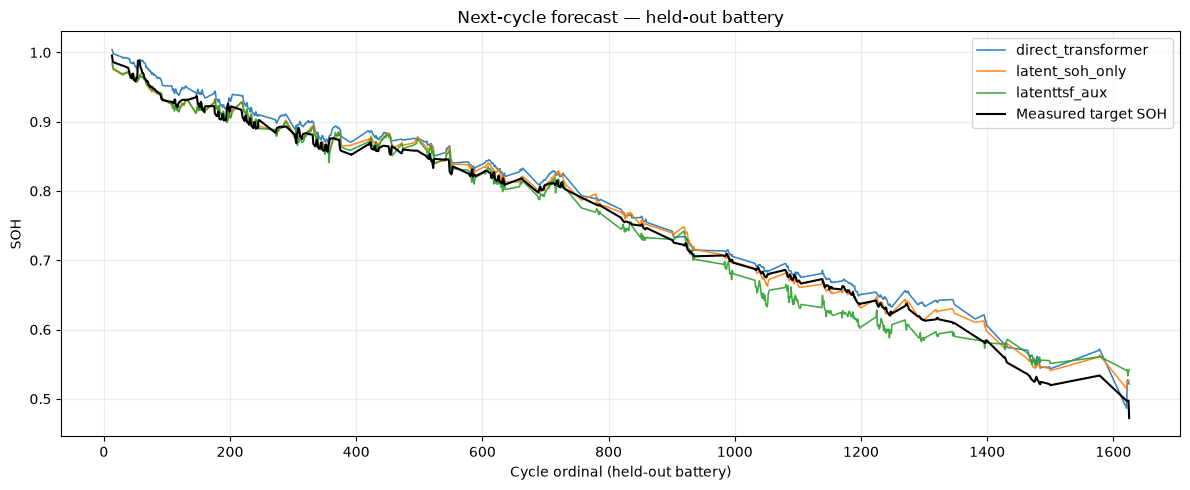

model,direct_transformer,latent_soh_only,latenttsf_aux,latent_aux_improvement_pct
seed,,,,
42,0.013526,0.021257,0.017845,-31.932076
123,0.013202,0.019384,0.019081,-44.526762
2026,0.014970,0.019821,0.016905,-12.928057


In [7]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,4))
for name in MODELS:
    h=pd.read_csv(OUT_DIR/f'{name}_seed{SEEDS[0]}_history.csv')
    ax.plot(h.epoch,h.validation_RMSE,label=name)
ax.set(xlabel='epoch',ylabel='Validation RMSE (fractional SOH)',title=f'Validation convergence — seed {SEEDS[0]}')
ax.grid(alpha=.25);ax.legend();fig.tight_layout()
fig.savefig(OUT_DIR/'validation_curves.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(12,5))
for name in MODELS:
    d=pd.read_csv(OUT_DIR/f'{name}_seed{SEEDS[0]}_test_predictions.csv').sort_values(['battery','cycle_ordinal'])
    ax.plot(d.cycle_ordinal,d.predicted_soh,label=name,linewidth=1.15,alpha=.9)
ax.plot(d.cycle_ordinal,d.soh,label='Measured target SOH',linewidth=1.5,color='black')
ax.set(xlabel='Cycle ordinal (held-out battery)',ylabel='SOH',title='Next-cycle forecast — held-out battery')
ax.legend();ax.grid(alpha=.25);fig.tight_layout()
fig.savefig(OUT_DIR/'test_next_cycle_predictions.png',dpi=180);plt.show()

per_battery=[]
for name in MODELS:
    for seed in SEEDS:
        d=pd.read_csv(OUT_DIR/f'{name}_seed{seed}_test_predictions.csv')
        for battery,g in d.groupby('battery'):
            e=g.predicted_soh.to_numpy()-g.soh.to_numpy()
            per_battery.append(dict(model=name,seed=seed,battery=battery,n=len(g),
                                    RMSE=np.sqrt(np.mean(e**2)),MAE=np.mean(np.abs(e))))
pd.DataFrame(per_battery).to_csv(OUT_DIR/'test_per_battery_metrics.csv',index=False)

# Per-seed validation paired comparisons against direct Transformer
v=metrics.query("split == 'validation'").pivot(index='seed',columns='model',values='RMSE')
v['latent_aux_improvement_pct'] = 100*(v['direct_transformer']-v['latenttsf_aux'])/v['direct_transformer']
v.to_csv(OUT_DIR/'paired_validation_comparison.csv')
display(v)

## 7. Reproducibility notes and next steps

In [8]:
config=dict(task='next-cycle SOH forecasting',input_cycle_window=SEQ_LEN,
            current_cycle_input_features_available=False,
            features=FEATURES,train_csv=str(paths['train']),validation_csv=str(paths['validation']),test_csv=str(paths['test']),
            max_gap_hours=MAX_GAP_HOURS,latent_dim=LATENT_DIM,d_model=D_MODEL,layers=N_LAYERS,
            seeds=SEEDS,epochs=EPOCHS,ae_epochs=AE_EPOCHS,
            lambda_latent=LAMBDA_LATENT,lambda_align=LAMBDA_ALIGN,device=str(DEVICE),
            caveat='Inspired by LatentTSF; not a faithful author-code reproduction. No measured-SOH smoothing; no rest labels.')
(OUT_DIR/'run_config.json').write_text(json.dumps(config,indent=2,default=list))
print('All outputs saved at:',OUT_DIR.resolve())
print('Research note: matched next-cycle forecast experiments only. Earlier current-cycle metrics are NOT comparable.')

All outputs saved at: C:\Projects\Battery_Soh\latenttsf_soh_results
Research note: matched next-cycle forecast experiments only. Earlier current-cycle metrics are NOT comparable.


### Interpretation guidance

- **Direct Transformer**: predicts next-cycle SOH directly from historical charging features.
- **Latent SOH only**: same past features encoded by a frozen autoencoder, then predicts next latent state and SOH but only receives SOH loss.
- **LatentTSF auxiliary**: adds latent-state target MSE and cosine alignment. Next-cycle features enter **only the training objective**, not the model input at inference.
- If latent auxiliary learning improves validation RMSE versus both controls across seeds, investigate longer horizons (24, 48) and different held-out battery folds. Otherwise the latent-state hypothesis remains unsupported for this task.
- Validation/test data preserve fluctuations. Their presence should be noted as a measurement limitation, not treated as proof of recovery.
- **Do not fit a latent autoencoder to all_data.csv**: that would expose held-out-battery feature distributions during training.
- Do not compare this next-cycle setup with the existing current-cycle Transformer result of RMSE 0.012754; they are different tasks. A current-cycle LatentTSF variant would need a separate, equally matched comparison.

**Reference:** Yang et al. (2026), *From Observations to States: Latent Time Series Forecasting*, ICML/PMLR 306, https://proceedings.mlr.press/v306/yang26y.html . Official implementation: https://github.com/Muyiiiii/LatentTSF .